In [3]:
%matplotlib notebook
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import time
import scipy.io as scio
import math
#import h5py
from matplotlib.colors import ListedColormap
import matplotlib.colors as colors
plt.rc('font', family='serif', size=14)

In [4]:
def run1(step1, step2, L, W, H, D1, D2):
    steps = random.randint(step1, step2)
    xyz = []
    x0 = random.randint(1, L//2)
    y0 = random.randint(1, W//2)
    z0 = random.randint(D1, D2)

    cur1 = [x0, y0, z0]
    cur2 = [x0+1, y0, z0]
    cur3 = [x0, y0+1, z0]
    cur4 = [x0+1, y0+1, z0]
    cur5 = [x0, y0, z0+1]
    cur6 = [x0+1, y0, z0+1]
    cur7 = [x0, y0+1, z0+1]
    cur8 = [x0+1, y0+1, z0+1]
    xyz.extend((cur1, cur2, cur3, cur4, cur5, cur6, cur7, cur8))

    for _ in range(steps):
        axis = random.randint(0, 2)
        stride = random.choice([-2, 2])
        cur1[axis] += stride
        cur2[axis] += stride
        cur3[axis] += stride
        cur4[axis] += stride
        cur5[axis] += stride
        cur6[axis] += stride
        cur7[axis] += stride
        cur8[axis] += stride

        if cur1[0] <= 1:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = 1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = 2
        if cur8[0] >= L:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = L//2 - 1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = L//2

        if cur1[1] <= 1:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = 1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = 2
        if cur8[1] >= W:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = W//2 -1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = W//2

        if cur1[2] <= D1:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D1+1
        if cur8[2] >= D2:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D2-1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D2

        xyz.extend((cur1[:], cur2[:], cur3[:], cur4[:], cur5[:], cur6[:], cur7[:], cur8[:]))
    return xyz


def run2(step1, step2, L, W, H, D1, D2):
    steps = random.randint(step1, step2)
    xyz = []
    x0 = random.randint(L//2+1, L)
    y0 = random.randint(W//2+1, W)
    z0 = random.randint(D1, D2)

    cur1 = [x0, y0, z0]
    cur2 = [x0+1, y0, z0]
    cur3 = [x0, y0+1, z0]
    cur4 = [x0+1, y0+1, z0]
    cur5 = [x0, y0, z0+1]
    cur6 = [x0+1, y0, z0+1]
    cur7 = [x0, y0+1, z0+1]
    cur8 = [x0+1, y0+1, z0+1]
    xyz.extend((cur1, cur2, cur3, cur4, cur5, cur6, cur7, cur8))

    for _ in range(steps):
        axis = random.randint(0, 2)
        stride = random.choice([-2, 2])
        cur1[axis] += stride
        cur2[axis] += stride
        cur3[axis] += stride
        cur4[axis] += stride
        cur5[axis] += stride
        cur6[axis] += stride
        cur7[axis] += stride
        cur8[axis] += stride

        if cur1[0] <= 1:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = L//2+1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = L//2+2
        if cur8[0] >= L:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = L-1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = L

        if cur1[1] <= 1:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = L//2+1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = L//2+2
        if cur8[1] >= W:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = W-1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = W

        if cur1[2] <= D1:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D1+1
        if cur8[2] >= D2:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D2-1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D2

        xyz.extend((cur1[:], cur2[:], cur3[:], cur4[:], cur5[:], cur6[:], cur7[:], cur8[:]))
    return xyz


def random_walk(path1, path2, step1, step2, L, W, H, D1, D2):
    model1 = run1(step1, step2, L, W, H, D1, D2)
    for i in range(len(model1)):
        model1[i].append(1) 
    model2 = run2(step1, step2, L, W, H, D1, D2)
    for i in range(len(model2)):
        model2[i].append(1) 
    np.savetxt(path1, model1, fmt="%d", delimiter='\t')
    np.savetxt(path2, model2, fmt="%d", delimiter='\t')

In [5]:
L = 32
W = 32
H = 16
D1 = 1
D2 = 16
step1 = 30
step2 = 40
number = 5500
syn_number = 400
path = r"./model/tra&val/"

In [6]:
start = time.time()
for i in range(0, number):
    path1 = path+ '1model{}.dat'.format(i)
    path2 = path+ '2model{}.dat'.format(i)
    random_walk(path1, path2, step1, step2, L, W, H, D1, D2)
end = time.time()
times = end - start
print('Cost times : %d s' %times)

Cost times : 18 s


In [7]:
def save_regular_models(model, path):
    m2 = []
    a = []
    for i, j in enumerate(model):
        for m, n in enumerate(j):
            for p, q in enumerate(n):
                if q == True:
                    a.extend([i, m, p])
                    m2.extend([a]) 
                    a = []
    for i in range(len(m2)):
            m2[i].append(1) 
    np.savetxt(path, m2, fmt="%d", delimiter='\t')
    
def run5(path1, path2):
    L, W, H = np.indices((32, 32, 16))
    lower = np.random.randint(3, 17)
    upper = lower + 4
    
    h0 = np.random.randint(1, 9)
    h1  = h0 + 6
    step = 2
    step2 = 10

    lower1 = np.random.randint(3, 23)
    upper1 = lower1 + 8

    model = (L < upper) & (L >= lower) & (W < upper1) & (W >= lower1) & (H < h1+step) & (H >= h0+step)
    save_regular_models(model, path1)

    model1 = (L < upper + step2) & (L >= lower + step2) & (W < upper1) & (W >= lower1) & (H < h1) & (H >= h0)
    save_regular_models(model1, path2)

In [8]:
for i in range(syn_number):
    path1 = r"./model/syn/1model{}.dat".format(i)
    path2 = r"./model/syn/2model{}.dat".format(i)
    run5(path1, path2)

In [9]:
def con_model(path):
    data = pd.read_table(path, sep = '\t', header=None, engine='python')
    model = np.zeros((32, 32, 16))
    for i in range(len(data)):
        index = data.iloc[i]
        x = index[0] - 1
        y = index[1] - 1
        z = index[2] - 1
        model[x][y][z] = index[3]
    model = model > 0
    return model    

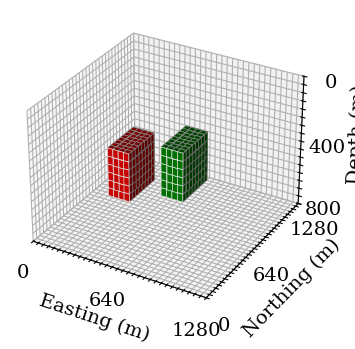

In [10]:
%matplotlib inline
path1 = r'./model/syn/1model{}.dat'.format(i)
path2 = r'./model/syn/2model{}.dat'.format(i)
model1 = con_model(path1)
model2 = con_model(path2)
model = model1 | model2
facecolors = np.empty(model.shape, dtype=object)
facecolors[model1] = "#E10000"
facecolors[model2] = "green"

fig = plt.figure(figsize = (8, 4))
ax = fig.add_subplot(111, projection='3d')

ax.voxels(model, facecolors=facecolors, edgecolors='w', linewidth=0.5)
plt.xticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_xlabel('Easting (m)')
plt.yticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_ylabel('Northing (m)')
ax.set_zticks(np.arange(0, 17, 1))
ax.set_zticklabels(['0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '400', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '800'])
ax.set_zlabel('Depth (m)')
ax.invert_zaxis()
plt.show()

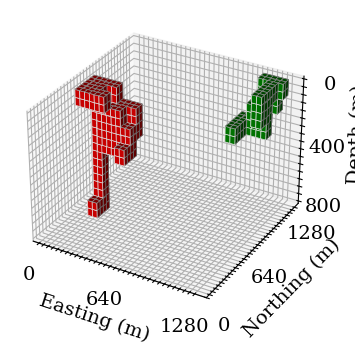

In [11]:
%matplotlib inline
path1 = r'./model/tra&val/1model{}.dat'.format(i)
path2 = r'./model/tra&val/2model{}.dat'.format(i)
model1 = con_model(path1)
model2 = con_model(path2)
model = model1 | model2
facecolors = np.empty(model.shape, dtype=object)
facecolors[model1] = "#E10000"
facecolors[model2] = "green"

fig = plt.figure(figsize = (8, 4))
ax = fig.add_subplot(111, projection='3d')

ax.voxels(model, facecolors=facecolors, edgecolors='w', linewidth=0.5)
plt.xticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_xlabel('Easting (m)')
plt.yticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_ylabel('Northing (m)')
ax.set_zticks(np.arange(0, 17, 1))
ax.set_zticklabels(['0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '400', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '800'])
ax.set_zlabel('Depth (m)')
ax.invert_zaxis()
plt.show()